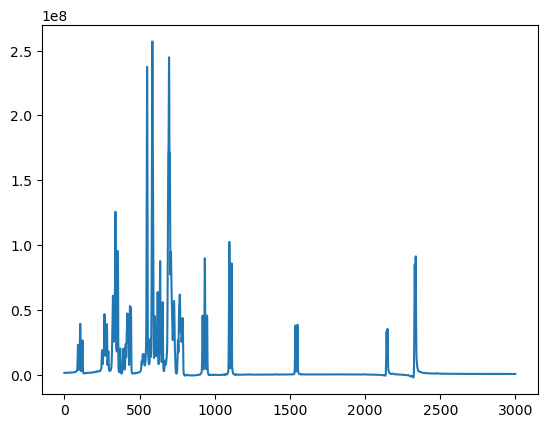

In [ ]:
import scipy.io as sio
import numpy as np
import matplotlib.pyplot as plt
import torch
import os
import logging
import random
import scipy.io as scio
from tqdm import tqdm
from torch.utils.data import Dataset
import data as Data
import model as Model
import argparse
import core.logger as Logger
import core.metrics as Metrics
from data import dataset

mat = sio.loadmat('/mnt/DATA1/shaojie/code/data/GSP_data.mat')

DOSYData = mat['DOSYData']  
b = mat['b'].squeeze()      
cs = mat['cs'].squeeze()    

plt.figure()
plt.plot(np.real(DOSYData[0][6500:9500]))
plt.show()

cs1 = 6500
cs2 = 7700
cs_crop = cs[cs1:cs2]

def add_noise_with_snr(signal, snr, seed=None):
    if seed is not None:
        np.random.seed(seed)
    signal = signal.astype(np.complex128)
    max_val = np.max(np.abs(signal))
    noise_std = max_val / (2.0 * snr)
    noise = noise_std * (
        np.random.randn(*signal.shape) + 1j * np.random.randn(*signal.shape)
    )
    noisy_signal = signal + noise
    return noisy_signal, noise

snr = 40
full_clean_dosy = DOSYData.astype(np.complex128)
full_noisy_dosy, full_noise = add_noise_with_snr(full_clean_dosy, snr, seed=0)

clean_dosy = full_clean_dosy[:, cs1:cs2]
noisy_dosy = full_noisy_dosy[:, cs1:cs2]

In [5]:

dim = 1
N1 = 256
max_J = 1
J = np.random.randint(1, max_J + 1, size=(dim, 1))
mask = np.zeros((dim, max_J))
mask[np.arange(dim), J.ravel() - 1] = 1
mask = np.cumsum(mask, axis=1)
A = np.random.uniform(0.05, 1.0, size=(dim, max_J))
w = np.random.uniform(0.3, 0.5, size=(dim, max_J))
sgm = np.random.uniform(399, 400, size=(dim, max_J))
t1 = np.arange(N1)
A = np.multiply(A, mask)
x1 = A[..., None] * np.exp(-t1 / sgm[..., None]) * np.exp(1j * 2 * np.pi * w[..., None] * t1)
clean_xn = np.sum(x1, axis=1)
spec = np.fft.fft(clean_xn)
norm_spec = spec / np.max(spec)

max_amp = np.max(np.abs(full_noisy_dosy))

DOSY_noisy = torch.complex(
    torch.from_numpy((noisy_dosy / max_amp).real).float(),
    torch.from_numpy((noisy_dosy / max_amp).imag).float()
)   
DOSY_clean = torch.complex(
    torch.from_numpy((clean_dosy / max_amp).real).float(),
    torch.from_numpy((clean_dosy / max_amp).imag).float()
)  
FULL_SPEC = torch.complex(
    torch.from_numpy((full_noisy_dosy / max_amp).real).float(),
    torch.from_numpy((full_noisy_dosy / max_amp).imag).float()
)  
norm_spec_t = torch.complex(
    torch.from_numpy(np.real(norm_spec.squeeze())).float(),
    torch.from_numpy(np.imag(norm_spec.squeeze())).float()
)   
FULL_FID = torch.fft.ifft(FULL_SPEC, dim=-1)   

In [ ]:
parser = argparse.ArgumentParser()
parser.add_argument('-c', '--config', type=str, default='config/sr_sr3_256_256_val.json',
                    help='JSON file for configuration')
parser.add_argument('-p', '--phase', type=str, choices=['train', 'val'], 
                    help='Run either train(training) or val(generation)', default='val')
parser.add_argument('-gpu', '--gpu_ids', type=str, default=None)
parser.add_argument('-debug', '-d', action='store_true')
parser.add_argument('-enable_wandb', action='store_true')
parser.add_argument('-log_wandb_ckpt', action='store_true')
parser.add_argument('-log_eval', action='store_true')
args =parser.parse_known_args()[0]
opt = Logger.parse(args)
opt = Logger.dict_to_nonedict(opt)

torch.backends.cudnn.enabled = True
torch.backends.cudnn.benchmark = True
Logger.setup_logger(None, opt['path']['log'],
                    'train', level=logging.INFO, screen=True)
Logger.setup_logger('val', opt['path']['log'], 'val', level=logging.INFO)
logger = logging.getLogger('base')
logger.info(Logger.dict2str(opt))

diffusion = Model.create_model(opt)
logger.info('Initial Model Finished')

current_step = diffusion.begin_step
current_epoch = diffusion.begin_epoch
n_iter = opt['train']['n_iter']

if opt['path']['resume_state']:
    logger.info('Resuming training from epoch: {}, iter: {}.'.format(
        current_epoch, current_step))
diffusion.set_new_noise_schedule(
    opt['model']['beta_schedule'][opt['phase']], schedule_phase=opt['phase'])


In [ ]:
avg_mse = 0.0
result_path = '{}/{}'.format(opt['path']['results'], 100)
os.makedirs(result_path, exist_ok=True)
diffusion.set_new_noise_schedule(opt['model']['beta_schedule']['val'], schedule_phase='val')
feed_data = {
    'DOSY_noisy': DOSY_noisy,
    'DOSY_clean': DOSY_clean,
    'FULL_SPEC': FULL_SPEC,
    'norm_spec': norm_spec_t,
    'lam_l1': torch.tensor(0.025, dtype=torch.float32),
    'lam_lr': torch.tensor(0.1, dtype=torch.float32),
}
feed_data = diffusion.set_device(feed_data)
diffusion.feed_data(feed_data)
diffusion.test(continous=False, pnp_mode='dosy')
visuals = diffusion.get_current_visuals()

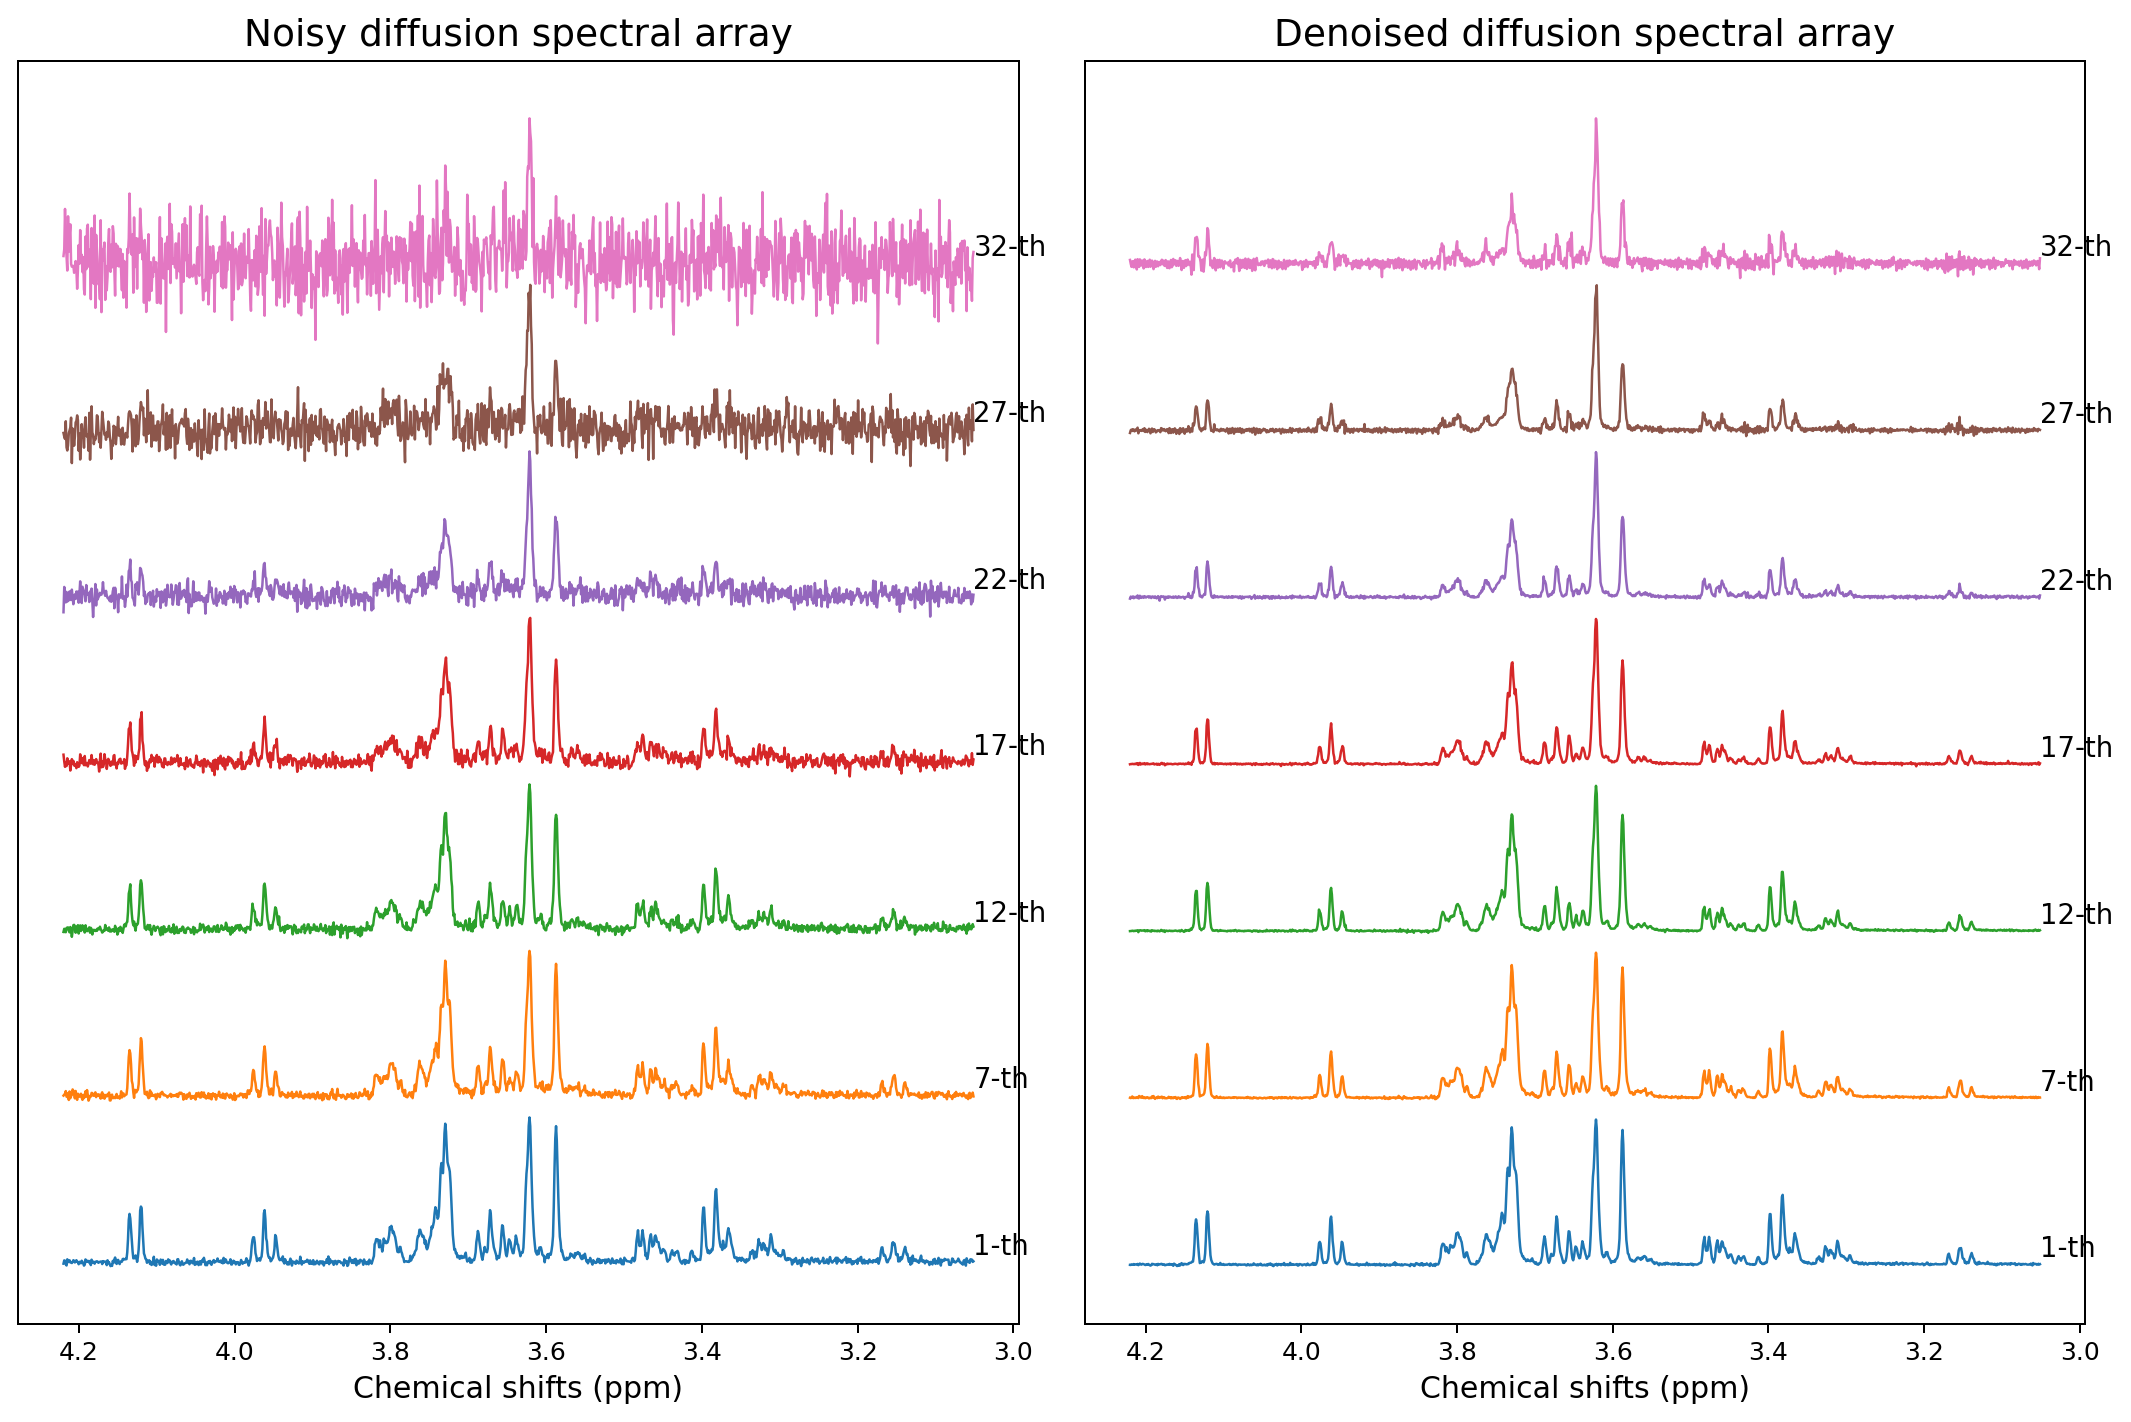

In [ ]:
dosy_noisy_vis = visuals['INF'].cpu().numpy()   
dosy_denoised_vis = visuals['SR'].cpu().numpy() 
dosy_clean_vis = visuals['HR'].cpu().numpy()  

def normalize_1d(x):
    x = np.real(x)
    return x / (np.max(np.abs(x)) + 1e-12)

selected_original_idx = [0, 6, 11, 16, 21, 26, 31]
def plot_stacked_two(dosy_left,
                     dosy_right,
                     cs_crop,
                     selected_idx=None,
                     step=1.15,
                     left_title='Noisy diffusion spectral array',
                     right_title='Denoised diffusion spectral array'):

    if selected_idx is None:
        selected_idx = list(range(dosy_left.shape[0]))
    plt.figure(figsize=(12, 8))

    ax1 = plt.subplot(1, 2, 1)
    for plot_order, idx in enumerate(selected_idx):
        y = normalize_1d(dosy_left[idx]) + plot_order * step
        ax1.plot(cs_crop, y, linewidth=1.0)
        ax1.text(cs_crop[0], plot_order * step + 0.05, f'{idx+1}-th', fontsize=11)
    ax1.set_title(left_title, fontsize=15)
    ax1.set_xlabel('Chemical shifts (ppm)', fontsize=12)
    ax1.set_yticks([])
    ax1.invert_xaxis()

    ax2 = plt.subplot(1, 2, 2)
    for plot_order, idx in enumerate(selected_idx):
        y = normalize_1d(dosy_right[idx]) + plot_order * step
        ax2.plot(cs_crop, y, linewidth=1.0)
        ax2.text(cs_crop[0], plot_order * step + 0.05, f'{idx+1}-th', fontsize=11)
    ax2.set_title(right_title, fontsize=15)
    ax2.set_xlabel('Chemical shifts (ppm)', fontsize=12)
    ax2.set_yticks([])
    ax2.invert_xaxis()
    plt.tight_layout()
    plt.show()

plot_stacked_two(
    dosy_left=dosy_noisy_vis,
    dosy_right=dosy_denoised_vis,
    cs_crop=cs_crop,
    selected_idx=selected_original_idx,
    step=1.15,
    left_title='Noisy diffusion spectral array',
    right_title='Denoised diffusion spectral array'
)

rmsd_list = []
for idx in selected_original_idx:
    recon_norm = normalize_1d(dosy_denoised_vis[idx])
    clean_norm = normalize_1d(dosy_clean_vis[idx])
    rmsd_i = np.sqrt(np.mean((clean_norm - recon_norm) ** 2))
    rmsd_list.append(rmsd_i)


In [ ]:

_gd = diffusion.netG.module if hasattr(diffusion.netG, 'module') else diffusion.netG
full_denoised = _gd.x_admm_full.cpu().numpy()     
full_noisy    = FULL_SPEC.cpu().numpy()        
full_clean    = full_clean_dosy / max_amp       

scio.savemat('./data/dosy_noisy_full_0.25_25_1200_1.mat', {
    'dosy_noisy'    : dosy_noisy_vis,   
    'full_noisy'    : full_noisy,        
    'b'             : b,
    'cs_crop'       : cs_crop,
    'cs'            : cs,
})
scio.savemat('./data/dosy_denoised_full_0.25_25_1200_1.mat', {
    'dosy_denoised' : dosy_denoised_vis, 
    'full_denoised' : full_denoised,    
})
scio.savemat('./data/dosy_clean_full_0.25_25_1200_1.mat', {
    'dosy_clean'    : dosy_clean_vis,    
    'full_clean'    : full_clean,        
})